## This is a sanity Check for NEW DELHI

In [29]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [31]:
flexpartoutput_filename = '/jetfs/scratch/gbrack/flexpart_output/new_delhi_10d_0.5deg/grid_time_20150525120000.nc'
era5_filename = '/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_Pr.nc'

In [50]:
era = xr.open_dataset(era5_filename)
flexpart = xr.open_dataset(flexpartoutput_filename)
partoutput = xr.open_mfdataset('/jetfs/scratch/gbrack/flexpart_output/new_delhi_10d_0.5deg/partoutput_*.nc')

In [51]:
era_clean = era.rename({'valid_time': 'time'})
era_aligned = era_clean.reindex_like(flexpart)

In [52]:
initial_cond = partoutput.isel(time=-1)
end_cond = partoutput.isel(time=0)

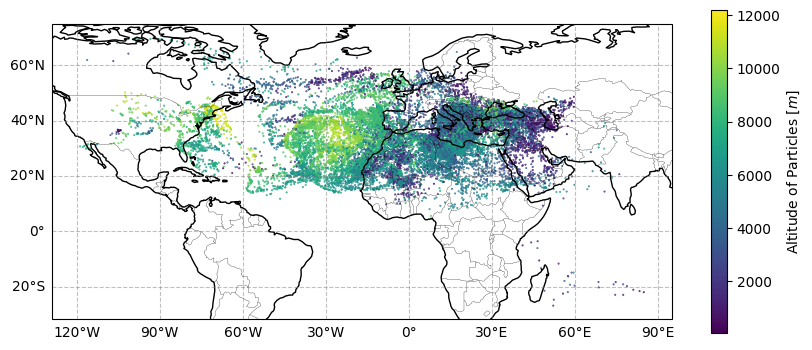

In [53]:
# lets look at the location of the particles at the first timestep

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

scatter = ax.scatter(initial_cond.lon_av, initial_cond.lat_av, s=0.2, transform=ccrs.PlateCarree(), c=initial_cond.z_av, cmap='viridis')

plt.colorbar(scatter, label=r'Altitude of Particles $[m]$', shrink=0.7)

gl = ax.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

In [54]:
cp = 1004.6
Lv = 2501000
g = 9.81

def mse(state):
    ground_height = flexpart.ORO.interp(
        longitude=((state.lon + 180) % 360) - 180,
        latitude=state.lat,
    )

    return(
        cp * state.T
        + Lv * state.sh
        + g * (state.z + ground_height)
    )

#MSE_initial = (cp * initial_cond.T_av) + (Lv * initial_cond.sh) + (g * initial_cond.z_av)
#MSE_end = (cp * end_cond.T_av) + (Lv * end_cond.sh) + (g * end_cond.z_av)

MSE_initial = mse(initial_cond)
MSE_end = mse(end_cond)


In [55]:
initial_cond

<xarray.Dataset> Size: 1MB
Dimensions:   (particle: 20000)
Coordinates:
  * particle  (particle) int32 80kB 1 2 3 4 5 ... 19996 19997 19998 19999 20000
    time      datetime64[ns] 8B 2015-05-15T12:00:00
Data variables:
    lon       (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    lon_av    (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    lat       (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    lat_av    (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    z         (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    z_av      (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    pv        (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    pv_av     (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    sh        (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    sh_av     (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    T         (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
    T_av      (particle) float32 80kB dask.array<chunksize=(20000,), meta=np.ndarray>
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    dace3af Mon Nov 24 10:17:47 2025 +0100
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-10-24 21:17 +0200  created by gbrack on jet1...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          2
    sfc_only:               0
    linit_cond:             2

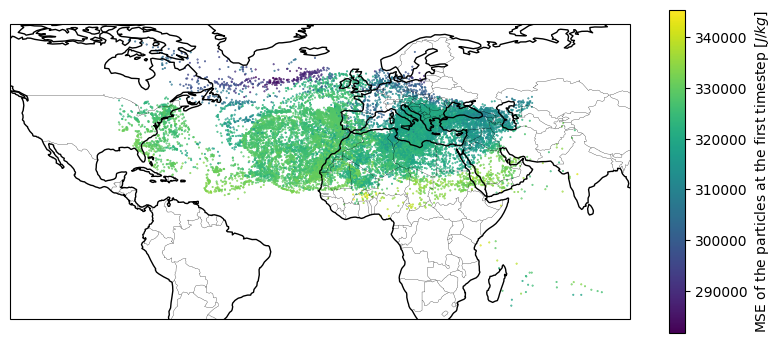

In [56]:
# let's look at the moist static energy of the particles at the first timestep

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

scatter = ax.scatter(initial_cond.lon_av, initial_cond.lat_av, s=0.2, transform=ccrs.PlateCarree(), c=MSE_initial, cmap='viridis')

plt.colorbar(scatter, label=r'MSE of the particles at the first timestep $[J/kg]$', shrink=0.7)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

In [57]:
absolute_initial_MSE = MSE_initial.mean().values
print(f'Absolute initial MSE: {absolute_initial_MSE:.1f} J/kg')

Absolute initial MSE: 322373.8 J/kg


In [58]:
absolute_end_MSE = MSE_end.mean().values
print(f'Absolute final MSE: {absolute_end_MSE:.1f} J/kg')

Absolute final MSE: 330496.1 J/kg


In [59]:
lon_initial = initial_cond.lon_av
lat_initial = initial_cond.lat_av


print(f"West: {lon_initial.min().values - 5}")  # Minus 5 for the safety buffer
print(f"East: {lon_initial.max().values + 5}")
print(f"South: {lat_initial.min().values - 5}")
print(f"North: {lat_initial.max().values + 5}")

West: -4.995943575631827
East: 364.9903869628906
South: -31.77669334411621
North: 75.2430419921875


## Now let's get that $\Delta E$

In [60]:
residence_time = flexpart['spec001_mr'].sel(height=100).squeeze()
sshf = era_aligned['sshf']
slhf = era_aligned['slhf']

In [61]:
dt = 3600
rho = 1.2

In [62]:
#hourly_sh = (residence_time * (sshf * -1.0)) / (dt * 100 * rho)
#hourly_lh = (residence_time * (slhf * -1.0)) / (dt * 100 * rho)

hourly_sh = (residence_time * (sshf * -1.0)) / (dt * 100)
hourly_lh = (residence_time * (slhf * -1.0)) / (dt * 100)

In [63]:
total_sensible_added = hourly_sh.sum().values
total_latent_added = hourly_lh.sum().values

total_energy_added = total_sensible_added + total_latent_added

In [67]:
print(f"Target to find: {(absolute_end_MSE - absolute_initial_MSE):.1f}")
print(f"Total Sensible Heat added: {total_sensible_added:.1f} J/kg")
print(f"Total Latent Heat added:   {total_latent_added:.1f} J/kg")
print(f"---")
print(f"TOTAL SURFACE FORCING:     {total_energy_added:.1f} J/kg")

Target to find: 8122.3
Total Sensible Heat added: 8486.8 J/kg
Total Latent Heat added:   6758.6 J/kg
---
TOTAL SURFACE FORCING:     15245.4 J/kg


In [69]:
print(((MSE_end - MSE_initial).mean(skipna=False)).compute().item())

nan


In [70]:
def mean_change(variable):
    return (
        end_cond[variable].astype("float64")
        - initial_cond[variable].astype("float64")
    ).mean(skipna=False).compute().item()

d_temperature = cp * mean_change("T")
d_humidity = Lv * mean_change("sh")
d_height = g * mean_change("z")

d_total = (
    MSE_end - MSE_initial
).mean(skipna=False).compute().item()

print("Temperatur:      ", d_temperature)
print("Feuchte:         ", d_humidity)
print("Höhe über Grund: ", d_height)
print("Bodenhöhe/Rest:  ", d_total - d_temperature - d_humidity - d_height)
print("Gesamt:          ", d_total)

Temperatur:       50229.327322225196
Feuchte:          7672.7073615813715
Höhe über Grund:  -49685.01178976776
Bodenhöhe/Rest:   nan
Gesamt:           nan


In [81]:
for name, state, energy in [
    ("Anfang", initial_cond, MSE_initial),
    ("Ende", end_cond, MSE_end),
]:
    ground = flexpart.ORO.interp(
        longitude=((state.lon + 180) % 360) - 180,
        latitude=state.lat,
    )

    print(name, "Zeit:", state.time.values)
    print("Fehlende Bodenhöhen:", ground.isnull().sum().compute().item())
    print("Fehlende MSE-Werte: ", energy.isnull().sum().compute().item())

Anfang Zeit: 2015-05-15T12:00:00.000000000
Fehlende Bodenhöhen: 173
Fehlende MSE-Werte:  173
Ende Zeit: 2015-05-25T11:00:00.000000000
Fehlende Bodenhöhen: 0
Fehlende MSE-Werte:  0


## Let's look at the $\Delta E$ distribution

In [71]:
# sum up energy uptake through time
total_sensible = hourly_sh.sum(dim='time')
total_latent = hourly_lh.sum(dim='time')

Text(0.5, 1.0, 'Total Sensible Heat Energy Accumulated over 10 Days')

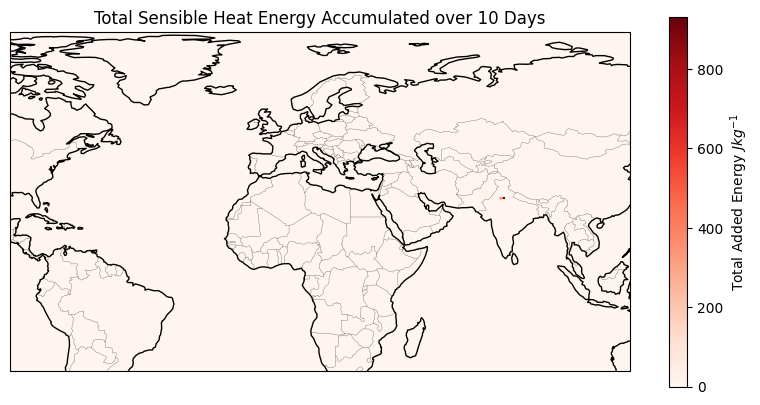

In [72]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

max_energy = total_sensible.max().values

my_min = 0
my_max = np.round(max_energy, 0)

mesh = ax.pcolormesh(total_sensible.longitude,
                     total_sensible.latitude,
                     total_sensible,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy $J kg^{-1}$')

ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)
ax.add_feature(cfeature.COASTLINE)

ax.set_title('Total Sensible Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Latent Heat Energy Accumulated over 10 Days')

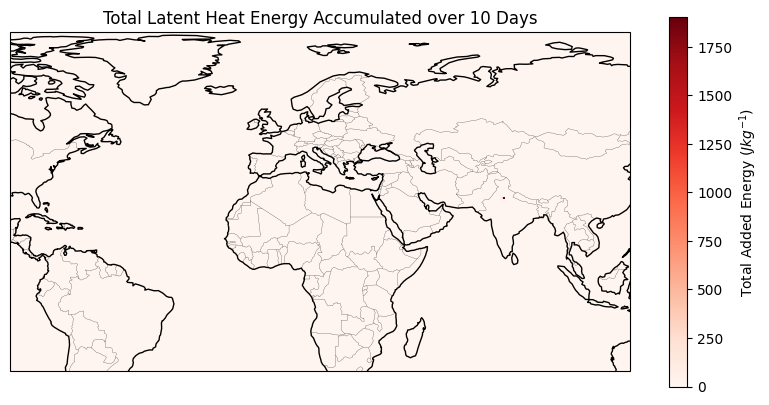

In [73]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

max_energy = total_latent.max().values

my_min = 0
my_max = np.round(max_energy, 0)

mesh = ax.pcolormesh(total_latent.longitude,
                     total_latent.latitude,
                     total_latent,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy ($J kg^{-1}$)')

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

ax.set_title('Total Latent Heat Energy Accumulated over 10 Days')

In [74]:
timeline_sh = hourly_sh.sum(dim=['latitude', 'longitude'])
timeline_lh = hourly_lh.sum(dim=['latitude', 'longitude'])

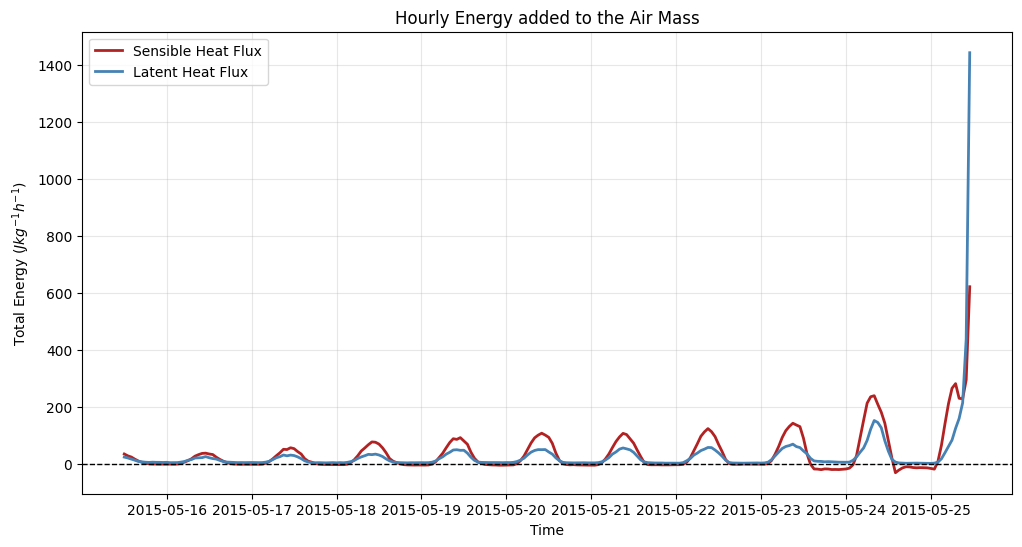

In [75]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.plot(timeline_sh.time,
        timeline_sh,
        color='firebrick',
        label='Sensible Heat Flux',
        lw=2
       )

ax.plot(timeline_lh.time,
        timeline_lh,
        color='steelblue',
        label='Latent Heat Flux',
        lw=2
       )

ax.axhline(0, c='k', lw='1', ls='--')

ax.set_title('Hourly Energy added to the Air Mass')
ax.set_ylabel(r'Total Energy ($J kg^{-1} h^{-1}$)')
ax.set_xlabel('Time')

ax.grid(True, alpha=0.3)
ax.legend()

## Okay let's do a little logarithmic scale to not ignore the starting point but also see other energy uptakes

Text(0.5, 1.0, 'Total Sensible Heat Energy Accumulated over 10 Days')

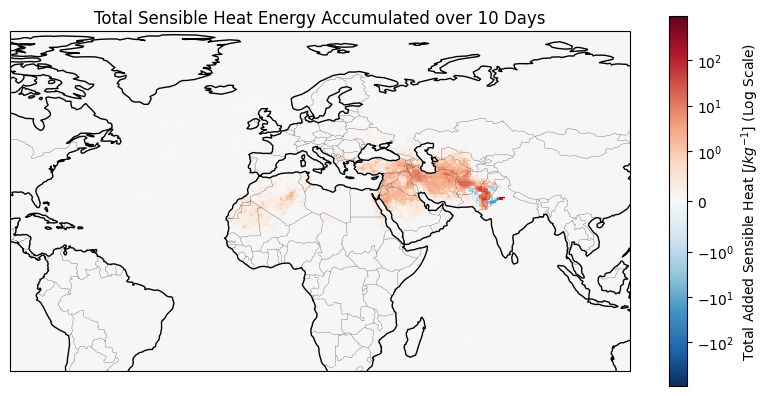

In [76]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_sensible.longitude,
                     total_sensible.latitude,
                     total_sensible,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_sensible.max(),
                                             vmax=total_sensible.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Sensible Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Sensible Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Latent Heat Energy Accumulated over 10 Days')

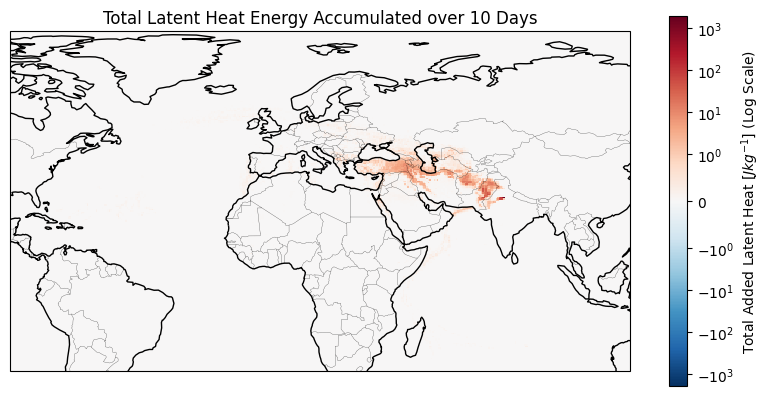

In [77]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_latent.longitude,
                     total_latent.latitude,
                     total_latent,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_latent.max(),
                                             vmax=total_latent.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Latent Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Latent Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Sensible and Latent Heat Energy Accumulated over 10 Days')

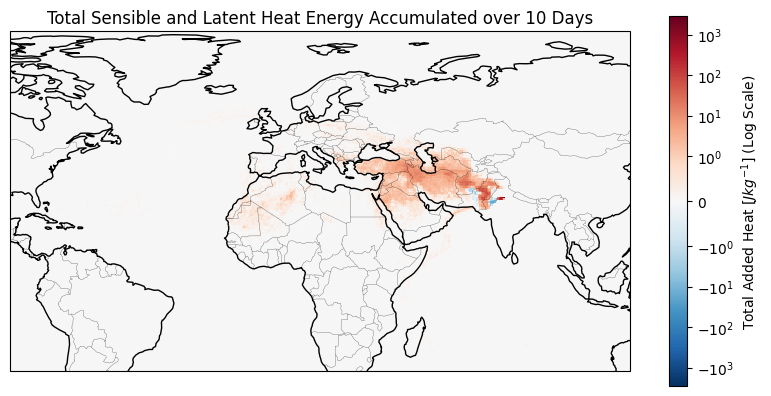

In [78]:
total_energy = total_latent + total_sensible

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_energy.longitude,
                     total_energy.latitude,
                     total_energy,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_energy.max(),
                                             vmax=total_energy.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Sensible and Latent Heat Energy Accumulated over 10 Days')

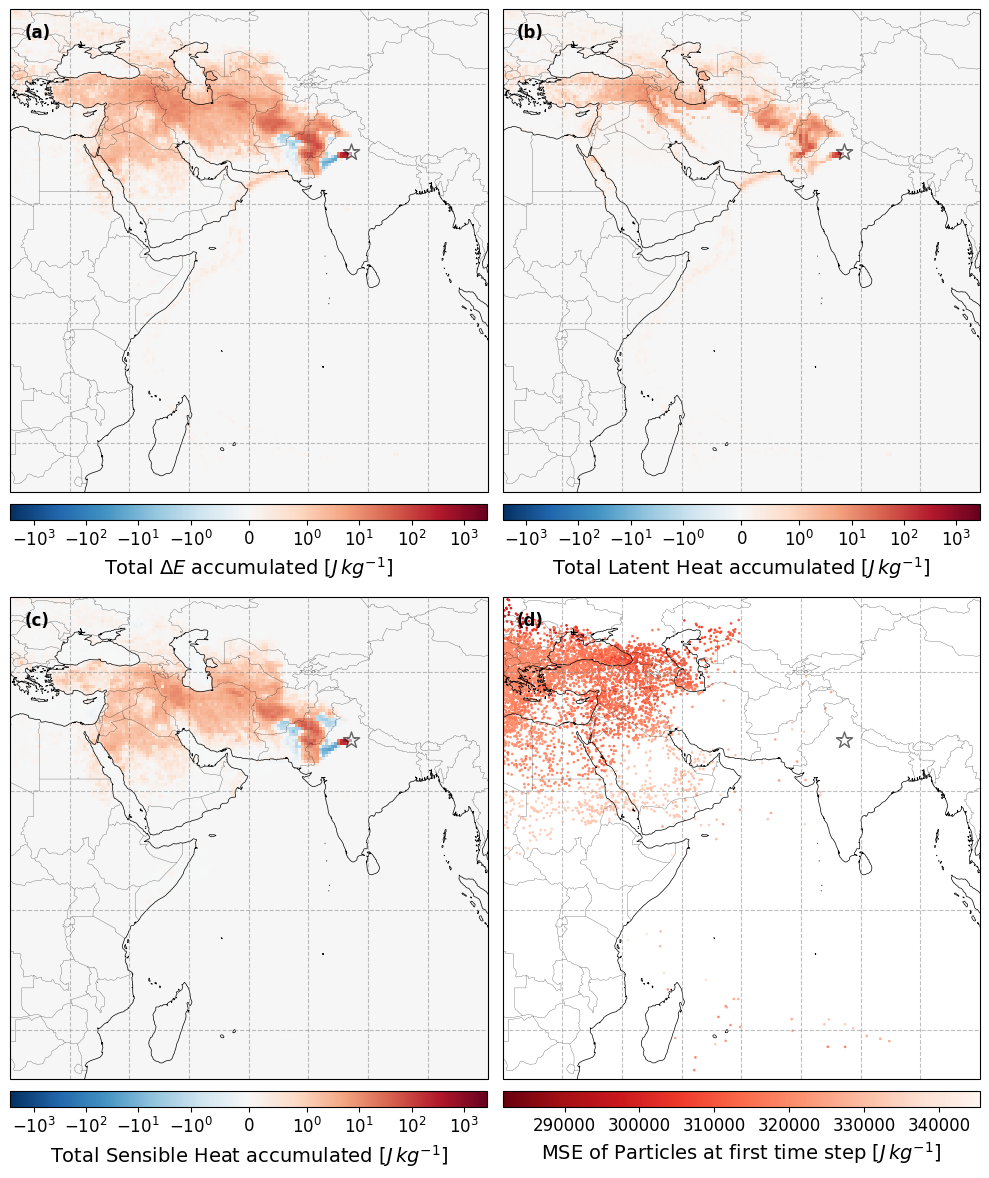

In [79]:
map_proj=ccrs.PlateCarree()

fig, axes = plt.subplots(2, 2, figsize=(10, 12), layout='tight',
                       subplot_kw={'projection': map_proj})

to_plot = [total_energy, total_latent, total_sensible, MSE_initial]
titles = [r'Total $\Delta E$ accumulated [$J \, kg^{-1}$]', r'Total Latent Heat accumulated [$J \, kg^{-1}$]', r'Total Sensible Heat accumulated [$J \, kg^{-1}$]', r'MSE of Particles at first time step [$J \, kg^{-1}$]']

for i in range(2):
    for o in range(2):
        ax = axes[i, o]
        if 2*i + o < 3:
            mesh = ax.pcolormesh(to_plot[2*i + o].longitude,
                                 to_plot[2*i + o].latitude,
                                 to_plot[2*i + o],
                                 transform=ccrs.PlateCarree(),
                                 cmap='RdBu_r',
                                 rasterized=True,
                                 norm=mcolors.SymLogNorm(linthresh=1.0,
                                                         vmin=-total_energy.max(),
                                                         vmax=total_energy.max(),
                                                         base=10
                                                         )
                                 )
            ax.set_extent([20, 100, -22.5, 45])
        else:
            mesh = ax.scatter(initial_cond.lon_av,
                              initial_cond.lat_av,
                              transform=map_proj,
                              cmap='Reds_r',
                              c=to_plot[2*i + o],
                              s=0.8,
                              )
            #ax.set_extent([-180, 180, -180, 180])
        
        ax.add_feature(cfeature.COASTLINE.with_scale('50m'), lw=0.5)
        ax.add_feature(cfeature.BORDERS.with_scale('50m'), lw=0.2, alpha=0.8)
        ax.set_extent([20, 100, -22.5, 45])
        subplot_label = f"({chr(ord('a') + 2*i + o)})" 
        axes[i][o].text(0.03, 0.97, subplot_label, 
                        transform=ax.transAxes, 
                        fontsize=12, 
                        fontweight='bold', 
                        va='top', 
                        ha='left')
        
        gl = ax.gridlines(draw_labels=False, color='gray', alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False
        gl.ylabel_style = {'size': 12}
        gl.xlabel_style = {'size': 12}
        
        ax.scatter(77.2089, 28.6139,
                   c='white',
                   edgecolor='black',
                   marker='*',
                   s=150,
                   label='New Delhi, India',
                   alpha=0.6
                   )
        
        cbar = plt.colorbar(mesh, 
                            ax=ax, 
                            aspect=30, 
#                            shrink=0.75, 
                            location='bottom', 
                            pad=0.02,
                            label=titles[2*i + o]
                           )
        cbar.set_label(titles[2*i + o], fontsize=14)
        cbar.ax.tick_params(labelsize=12)


plt.savefig('New_Delhi_new.pdf')

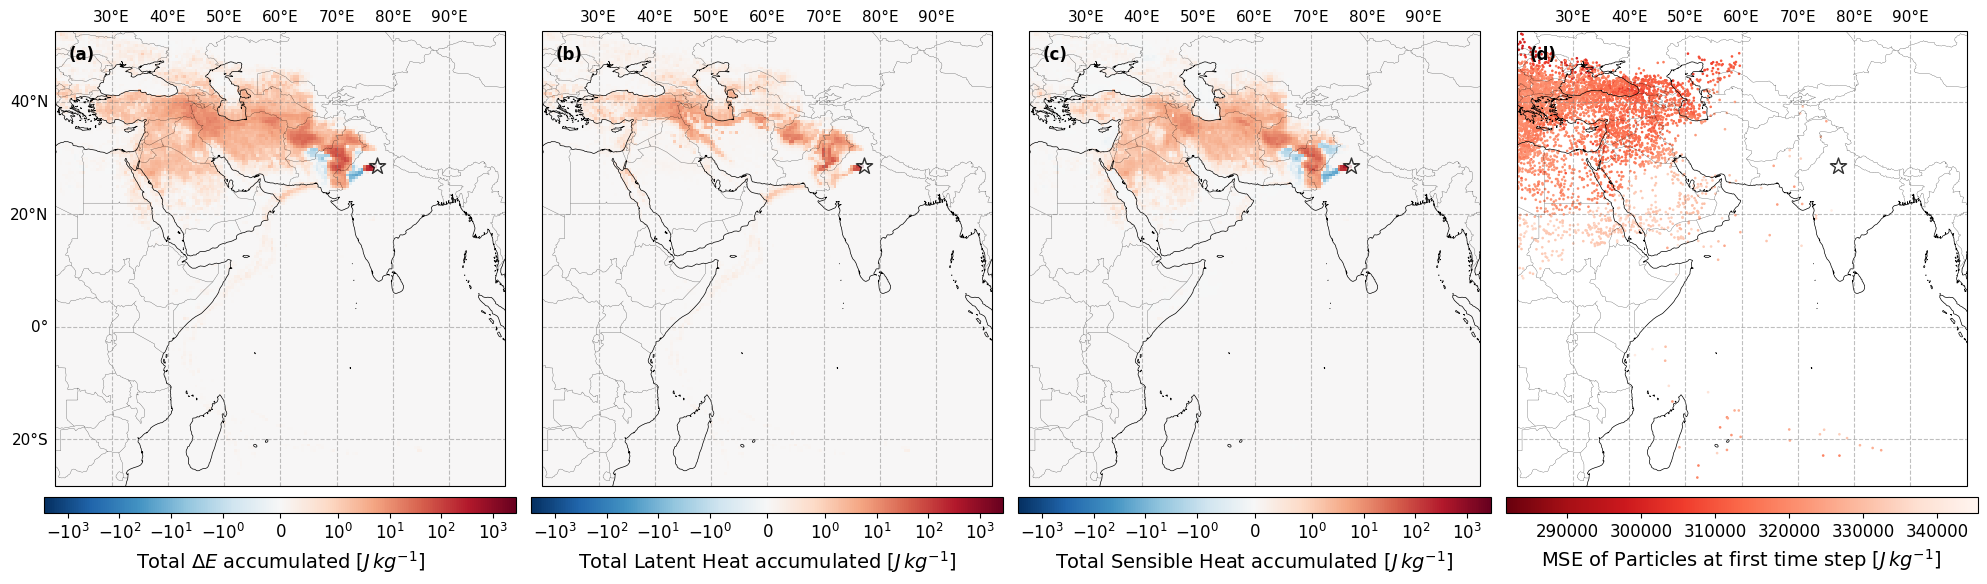

In [80]:
map_proj=ccrs.PlateCarree()

fig, axes = plt.subplots(1, 4, figsize=(20, 6), layout='tight',
                       subplot_kw={'projection': map_proj})

to_plot = [total_energy, total_latent, total_sensible, MSE_initial]
titles = [r'Total $\Delta E$ accumulated [$J \, kg^{-1}$]', r'Total Latent Heat accumulated [$J \, kg^{-1}$]', r'Total Sensible Heat accumulated [$J \, kg^{-1}$]', r'MSE of Particles at first time step [$J \, kg^{-1}$]']

for i in range(4):
    ax = axes[i]
    if i < 3:
        mesh = ax.pcolormesh(to_plot[i].longitude,
                             to_plot[i].latitude,
                             to_plot[i],
                             transform=ccrs.PlateCarree(),
                             cmap='RdBu_r',
                             rasterized=True,
                             norm=mcolors.SymLogNorm(linthresh=1.0,
                                                     vmin=-total_energy.max(),
                                                     vmax=total_energy.max(),
                                                     base=10
                                                     )
                             )
        ax.set_extent([20, 100, -22.5, 45])
    else:
        mesh = ax.scatter(initial_cond.lon_av,
                          initial_cond.lat_av,
                          transform=map_proj,
                          cmap='Reds_r',
                          c=to_plot[i],
                          s=0.8,
                          )
        ax.set_extent([20, 100, -22.5, 45])

    ax.add_feature(cfeature.COASTLINE.with_scale('50m'), lw=0.5)
    ax.add_feature(cfeature.BORDERS.with_scale('50m'), lw=0.2, alpha=0.8)
    ax.set_extent([20, 100, -22.5, 45])
    subplot_label = f"({chr(ord('a') + i)})" 
    axes[i].text(0.03, 0.97, subplot_label, 
                 transform=ax.transAxes, 
                 fontsize=12, 
                 fontweight='bold', 
                 va='top', 
                 ha='left')

    gl = ax.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--')
    gl.bottom_labels = False
    gl.right_labels = False
    if i == 0:
        gl.left_labels = True
    else:
        gl.left_labels = False
    gl.ylabel_style = {'size': 11}
    gl.xlabel_style = {'size': 11}

    ax.scatter(77.2089, 28.6139,
               c='white',
               edgecolor='black',
               marker='*',
               s=150,
               label='Karachi, Pakistan',
               alpha=0.8
               )

    cbar = plt.colorbar(mesh, 
                        ax=ax, 
                        aspect=30, 
                        location='bottom', 
                        pad=0.02,
                        label=titles[i]
                       )
    cbar.set_label(titles[i], fontsize=14)
    cbar.ax.tick_params(labelsize=12)

plt.savefig('New_Delhi_new.pdf')